# 2. Peeking, sequential testing, SRM and novelty effects

Notebook 01 assumed a clean experiment that is read once at the end. In practice there are four common ways this goes wrong:

| Section | Problem | What happens |
|---|---|---|
| 1 | Peeking at the results every day | false positives go from 5% to over 25% |
| 2 | Fixes: group sequential boundaries and always-valid inference (mSPRT) | what they cost in power and time |
| 3 | SRM caused by a logging bug | a fake win that the metric itself can't reveal |
| 4 | Novelty effect | the first weeks overstate the long-run effect |

It's the same simulated paywall as notebook 01, so every claim can be checked against the truth. All data is simulated.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

from src.simulator import simulate, SimConfig
from src import analysis as an, sequential as seq

from src.plotting import use_style, SURFACE, INK, INK2, MUTED, GRID, AXIS, BLUE, ORANGE
use_style()
pd.options.display.float_format = "{:,.4f}".format

df = simulate(SimConfig())                       # same 200k-user experiment as notebook 01
N_DAYS, N_USERS, N_REPS = 28, 40_000, 2000
day = df.enroll_day.to_numpy()
y0, _ = an.potential_outcomes(df, "revenue_30d")  # potential outcome without the discount

## 1. Peeking

The habit: users enroll over 28 days, the dashboard updates every day, someone checks it each morning and stops the test the first time p < 0.05.

A p-value controls the error rate of one planned look. As data comes in, the z-statistic moves around like a random walk, and with enough looks it will cross ±1.96 by chance. Every extra look is one more lottery ticket.

To measure it I run 2,000 A/A tests (no real effect, the "treatment" is just a coin flip on the same users), each with 40,000 users arriving over 28 days, and record the z-statistic at the end of every day.

In [2]:
_, _, z_aa = seq.simulate_sequential(y0, y0, day, N_USERS, N_REPS, N_DAYS, seed=1)      # A/A: y1 = y0
_, _, z_ef = seq.simulate_sequential(y0, y0 + 0.15, day, N_USERS, N_REPS, N_DAYS, seed=2)  # hypothetical true effect +0.15 EUR/user

def look_days(k):                                   # k evenly spaced looks, the last one on day 28
    return (np.ceil(N_DAYS * np.arange(1, k + 1) / k).astype(int) - 1)

rows = []
for k in [1, 2, 4, 7, 14, 28]:
    cols = look_days(k)
    rows.append({"looks": k, "false-positive rate (A/A)": (np.abs(z_aa[:, cols]) > 1.96).any(axis=1).mean()})
fpr = pd.DataFrame(rows).set_index("looks")
display(fpr.T)
print("Reference (Armitage, McPherson & Rowe 1969, normal data): 2 looks 8%, 5 looks 14%, 10 looks 19%, 20 looks 25%")

looks,1,2,4,7,14,28
false-positive rate (A/A),0.0515,0.0780,0.1195,0.1670,0.2115,0.2565


Reference (Armitage, McPherson & Rowe 1969, normal data): 2 looks 8%, 5 looks 14%, 10 looks 19%, 20 looks 25%


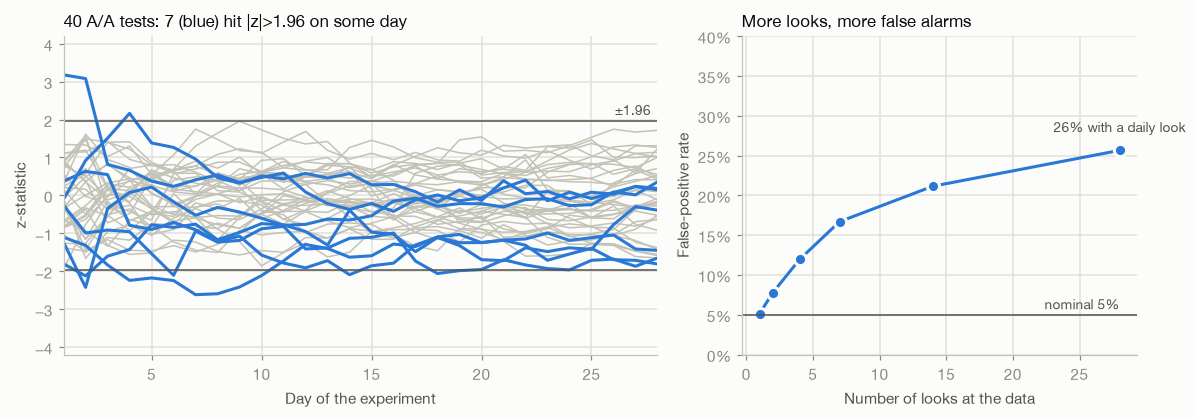

In [3]:
crossed = (np.abs(z_aa) > 1.96).any(axis=1)
rng = np.random.default_rng(0)
pick = rng.choice(N_REPS, 40, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.5, 1]})

ax = axes[0]
x = np.arange(1, N_DAYS + 1)
for i in pick:
    if not crossed[i]:
        ax.plot(x, z_aa[i], color=AXIS, lw=1)
for i in pick:
    if crossed[i]:
        ax.plot(x, z_aa[i], color=BLUE, lw=2)
for c in (-1.96, 1.96):
    ax.axhline(c, color=INK2, lw=1)
ax.set_ylim(-4.2, 4.2); ax.set_xlim(1, N_DAYS)
ax.text(N_DAYS - 0.3, 2.12, "±1.96", color=INK2, fontsize=9, ha="right")
ax.set_xlabel("Day of the experiment"); ax.set_ylabel("z-statistic")
ax.set_title(f"40 A/A tests: {crossed[pick].sum()} (blue) hit |z|>1.96 on some day", loc="left", fontsize=11, color=INK)

ax = axes[1]
ax.plot(fpr.index, fpr.iloc[:, 0], color=BLUE, lw=2, marker="o", ms=8, mec=SURFACE, mew=2)
ax.axhline(0.05, color=INK2, lw=1); ax.text(28, 0.057, "nominal 5%", color=INK2, fontsize=9, ha="right")
ax.annotate(f"{fpr.iloc[-1,0]:.0%} with a daily look", (28, fpr.iloc[-1, 0]), xytext=(0, 12), textcoords="offset points", ha="center", color=INK2, fontsize=9)
ax.set_ylim(0, 0.4); ax.set_xlabel("Number of looks at the data"); ax.set_ylabel("False-positive rate")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("More looks, more false alarms", loc="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig("../reports/figures/02_peeking.png", dpi=160); plt.show()

With a single look the error rate is 5%, as promised. With a daily look about one A/A test in four declares a winner that doesn't exist.

## 2. Two fixes if you need to look

Group sequential designs (Pocock, O'Brien-Fleming): you plan K looks in advance and raise the bar at each one so that the overall false positive rate stays at 5%. Pocock uses the same bar every time. O'Brien-Fleming (OBF) is very strict at the beginning and close to 1.96 at the end, so it loses little power at the final look. I find the boundaries by simulating random walks under H0 and check them against the published values.

Always-valid inference (mSPRT): the mixture sequential probability ratio test gives a statistic $\Lambda_n$ that is a martingale under H0, so $P(\Lambda_n \ge 1/\alpha \text{ for some } n)\le\alpha$ however often you look, with no schedule. Many commercial experimentation platforms use a version of it. It needs a prior scale $\tau$ for the effect; I use $\tau = 0.10$ € (about 11% of ARPU).

In [4]:
poc4 = seq.calibrate_boundary(4, "pocock", n_paths=400_000, seed=1)
obf4 = seq.calibrate_boundary(4, "obf",    n_paths=400_000, seed=1)
print("K=4 looks, two-sided alpha=5%")
print(f"  Pocock constant      : {poc4[0]:.3f}   (published 2.361)")
print(f"  O'Brien-Fleming bounds: {np.round(obf4, 3)}   (published C = 2.024 -> 4.049, 2.863, 2.337, 2.024)")

poc28 = seq.calibrate_boundary(28, "pocock", n_paths=200_000, seed=2)
obf28 = seq.calibrate_boundary(28, "obf",    n_paths=200_000, seed=2)
print(f"\nK=28 daily looks: Pocock constant {poc28[0]:.3f}; OBF from {obf28[0]:.2f} (day 1) down to {obf28[-1]:.3f} (day 28)")

K=4 looks, two-sided alpha=5%
  Pocock constant      : 2.361   (published 2.361)
  O'Brien-Fleming bounds: [4.045 2.86  2.335 2.022]   (published C = 2.024 -> 4.049, 2.863, 2.337, 2.024)

K=28 daily looks: Pocock constant 2.723; OBF from 11.37 (day 1) down to 2.149 (day 28)


In [5]:
TAU2, ALPHA = 0.10 ** 2, 0.05
wk = look_days(4)

def first_hit(mask):                                  # mask: reps x days -> (rejected?, day of decision)
    hit = mask.any(axis=1)
    return hit, np.where(hit, mask.argmax(axis=1) + 1, N_DAYS)

def masks(z, diff, se):
    az = np.abs(z)
    out = {}
    only_last = np.zeros_like(az, bool); only_last[:, -1] = az[:, -1] > 1.96
    out["Fixed horizon: one look at day 28"] = only_last
    out["Peeking daily at 1.96 (WRONG)"] = az > 1.96
    m = np.zeros_like(az, bool); m[:, wk] = az[:, wk] > 1.96
    out["Peeking weekly at 1.96 (WRONG)"] = m
    m = np.zeros_like(az, bool); m[:, wk] = az[:, wk] > poc4
    out["Pocock, 4 weekly looks"] = m
    m = np.zeros_like(az, bool); m[:, wk] = az[:, wk] > obf4
    out["O'Brien-Fleming, 4 weekly looks"] = m
    out["O'Brien-Fleming, 28 daily looks"] = az > obf28
    out["mSPRT, daily (always valid)"] = seq.msprt_lambda(diff, se, TAU2) >= 1 / ALPHA
    return out

d_aa, s_aa, z_aa = seq.simulate_sequential(y0, y0,        day, N_USERS, N_REPS, N_DAYS, seed=1)
d_ef, s_ef, z_ef = seq.simulate_sequential(y0, y0 + 0.15, day, N_USERS, N_REPS, N_DAYS, seed=2)
m_aa, m_ef = masks(z_aa, d_aa, s_aa), masks(z_ef, d_ef, s_ef)

rows = []
for name in m_aa:
    fp, _ = first_hit(m_aa[name]); pw, days_ = first_hit(m_ef[name])
    rows.append({"design": name, "false-positive rate (A/A)": fp.mean(), "power (true effect +0.15)": pw.mean(),
                 "avg days to decision": days_.mean()})
summary = pd.DataFrame(rows).set_index("design")
display(summary.style.format({"false-positive rate (A/A)": "{:.1%}", "power (true effect +0.15)": "{:.1%}", "avg days to decision": "{:.1f}"}))

,false-positive rate (A/A),power (true effect +0.15),avg days to decision
design,,,
Fixed horizon: one look at day 28,5.1%,85.4%,28.0
Peeking daily at 1.96 (WRONG),25.7%,92.7%,10.3
Peeking weekly at 1.96 (WRONG),11.9%,88.5%,16.4
"Pocock, 4 weekly looks",4.9%,78.6%,19.4
"O'Brien-Fleming, 4 weekly looks",5.3%,85.5%,21.9
"O'Brien-Fleming, 28 daily looks",5.0%,84.7%,19.9
"mSPRT, daily (always valid)",0.4%,57.1%,22.3


How much does mSPRT depend on $\tau$? The true effect in this scenario is +0.15 €, and $\tau$ is basically the size of effect you expect to find.

In [6]:
rows = []
for tau in [0.03, 0.05, 0.10, 0.15, 0.30, 0.60]:
    fp, _ = first_hit(seq.msprt_lambda(d_aa, s_aa, tau**2) >= 1 / ALPHA)
    pw, dd = first_hit(seq.msprt_lambda(d_ef, s_ef, tau**2) >= 1 / ALPHA)
    rows.append({"tau (EUR)": tau, "false-positive rate (A/A)": fp.mean(), "power (true effect +0.15)": pw.mean(), "avg days to decision": dd.mean()})
display(pd.DataFrame(rows).set_index("tau (EUR)").style.format({"false-positive rate (A/A)": "{:.1%}", "power (true effect +0.15)": "{:.1%}", "avg days to decision": "{:.1f}"}))

,false-positive rate (A/A),power (true effect +0.15),avg days to decision
tau (EUR),,,
0.030000,0.0%,6.2%,27.8
0.050000,0.1%,32.8%,25.9
0.100000,0.4%,57.1%,22.3
0.150000,1.0%,60.2%,21.3
0.300000,1.4%,57.0%,20.9
0.600000,1.1%,50.4%,21.8


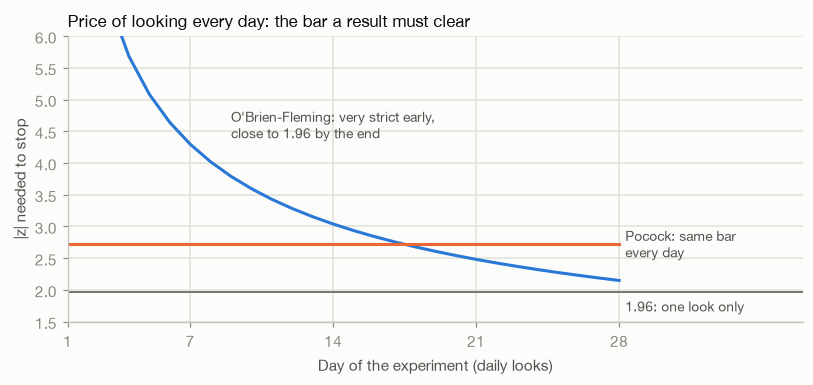

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(1, N_DAYS + 1)
ax.axhline(1.96, color=INK2, lw=1); ax.text(N_DAYS + 0.3, 1.74, "1.96: one look only", color=INK2, fontsize=9, va="center")
ax.plot(x, obf28, color=BLUE, lw=2);  ax.text(9, 4.6, "O'Brien-Fleming: very strict early,\nclose to 1.96 by the end", color=INK2, fontsize=9, va="center")
ax.plot(x, poc28, color=ORANGE, lw=2); ax.text(N_DAYS + 0.3, poc28[-1], "Pocock: same bar\nevery day", color=INK2, fontsize=9, va="center")
ax.set_ylim(1.5, 6); ax.set_xlim(1, 37); ax.set_xticks([1, 7, 14, 21, 28]); ax.set_xlabel("Day of the experiment (daily looks)"); ax.set_ylabel("|z| needed to stop")
ax.set_title("Price of looking every day: the bar a result must clear", loc="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig("../reports/figures/02_boundaries.png", dpi=160); plt.show()

From the tables:
- Both peeking rows break the 5% promise, while every sequential design keeps it (up to simulation noise).
- Group sequential designs can stop early when the effect is large: the average time to a decision is about 20-22 days instead of 28.
- OBF is the usual default for A/B tests because it costs almost no power (~85%, same as the fixed test). Pocock stops earlier on average (19 days) but ends with less power (~79%).
- mSPRT is valid but conservative. With $\tau = 0.10$ its false positive rate is only ~0.4% and power ~57%, which is the price of staying valid under unlimited checking. Power depends a lot on $\tau$: it peaks around 60% when $\tau$ matches the true 0.15, and guessing too large costs much less than guessing too small ($\tau = 0.03$ leaves ~6% power).
- The daily peeking row has the highest "power" and the shortest time, but with 26% false positives those numbers mean nothing.
- A limitation of my implementation: I assume the information arrives evenly (users per day are about constant here). With uneven traffic you'd need alpha spending (Lan-DeMets) on the actual information fraction.

## 3. SRM: when the experiment itself is broken

Suppose there's a logging bug: in the variant arm, 30% of the least engaged users (bottom quartile of pre-experiment sessions) never get logged, for example because the app crashes on the new paywall before the exposure event is sent. Those users silently disappear from the treatment data.

In [8]:
rng = np.random.default_rng(7)
q = df.sessions_pre.quantile([.25, .50, .75]).to_numpy()
low = df.sessions_pre <= q[0]
dropped = (df.treatment == 1) & low & (rng.random(len(df)) < 0.30)
bug = df[~dropped].copy()
print(f"Users lost: {dropped.sum():,}  ({dropped.sum() / (df.treatment == 1).sum():.1%} of the treatment arm)")

p_srm = an.srm_check(int(bug.treatment.sum()), int((1 - bug.treatment).sum()))
print(f"Treatment {bug.treatment.sum():,} vs control {(1 - bug.treatment).sum():,}  ->  SRM p-value = {p_srm:.2e}")

bug["sessions_bucket"] = pd.cut(bug.sessions_pre, [-1, q[0], q[1], q[2], np.inf], labels=["Q1 (least active)", "Q2", "Q3", "Q4"])
loc = bug.groupby("sessions_bucket", observed=True).treatment.agg(["size", "mean"]).rename(columns={"size": "n", "mean": "share in treatment"})
loc["SRM p-value"] = [an.srm_check(int(g.treatment.sum()), int((1 - g.treatment).sum())) for _, g in bug.groupby("sessions_bucket", observed=True)]
display(loc)

Users lost: 7,794  (7.8% of the treatment arm)
Treatment 92,267 vs control 99,939  ->  SRM p-value = 1.45e-68


,n,share in treatment,SRM p-value
sessions_bucket,,,
Q1 (least active),44548,0.4140,0.0000
Q2,50290,0.4986,0.5442
Q3,54928,0.5004,0.8511
Q4,42440,0.5009,0.6978


In [9]:
true_ate = df.true_ite_revenue_30d.mean()
clean = an.diff_in_means(df.revenue_30d.to_numpy(), df.treatment.to_numpy())
dirty = an.diff_in_means(bug.revenue_30d.to_numpy(), bug.treatment.to_numpy())
dirty_cuped, _ = an.cuped_effect(bug.revenue_30d.to_numpy(), bug.revenue_pre_30d.to_numpy(), bug.treatment.to_numpy())
smd = an.standardized_mean_diff(bug.sessions_pre.to_numpy().astype(float), bug.treatment.to_numpy())

print(f"TRUE effect                       : {true_ate:+.4f}")
print(f"Clean data, naive                 : {clean}")
print(f"Buggy data, naive                 : {dirty}")
print(f"Buggy data, CUPED                 : {dirty_cuped}")
print(f"\nBalance check on sessions_pre (SMD) after the bug: {smd:+.3f}  (clean data was ~0.00)")

TRUE effect                       : -0.0145
Clean data, naive                 : -0.0121  95% CI [-0.0562, +0.0320]  se=0.0225  p=0.590
Buggy data, naive                 : +0.0252  95% CI [-0.0204, +0.0707]  se=0.0232  p=0.279
Buggy data, CUPED                 : +0.0080  95% CI [-0.0329, +0.0489]  se=0.0209  p=0.702

Balance check on sessions_pre (SMD) after the bug: +0.081  (clean data was ~0.00)


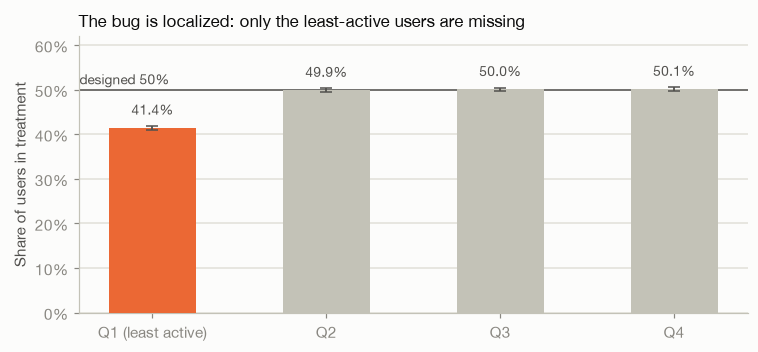

In [10]:
fig, ax = plt.subplots(figsize=(7.0, 3.3))
share = loc["share in treatment"]; n = loc["n"]
se = np.sqrt(0.25 / n)
colors = [ORANGE] + [AXIS] * 3
xs = np.arange(len(share))
ax.axhline(0.5, color=INK2, lw=1); ax.text(-0.42, 0.512, "designed 50%", color=INK2, fontsize=9, ha="left")
ax.bar(xs, share, width=0.5, color=colors, zorder=3)
ax.errorbar(xs, share, yerr=1.96 * se, fmt="none", ecolor=INK2, elinewidth=1.2, capsize=4, zorder=4)
for x_, s_ in zip(xs, share):
    ax.text(x_, s_ + 0.03, f"{s_:.1%}", ha="center", color=INK2, fontsize=9)
ax.set_xticks(xs, loc.index); ax.set_ylim(0, 0.62); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("Share of users in treatment")
ax.set_title("The bug is localized: only the least-active users are missing", loc="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig("../reports/figures/02_srm_localization.png", dpi=160); plt.show()

- The SRM test fires with an absurdly small p-value (the convention is to distrust the experiment below 0.001), and splitting by a pre-experiment variable shows that the problem is all in the least active users.
- On the buggy data the estimate moves from -0.012 to +0.025 (truth: -0.015). The treatment arm lost its low-revenue users, so it looks richer and the sign flips. Here it's not significant, but the bias stays the same as the sample grows while the standard error shrinks, so in a bigger experiment the same bug would produce a significant fake win.
- CUPED reduces the bias but doesn't remove it (+0.008), because it assumes the two arms are comparable and here they aren't.
- The covariate balance check is much less sensitive than the SRM test: the SMD on sessions only moves to +0.08, below the usual 0.1 alarm, while the SRM p-value is ~1e-68. That's why I run the SRM test first.
- What to do: don't ship and don't just reweight the data. Find the cause (instrumentation, crashes, redirects, bot filtering), fix it and run the test again. An SRM is a problem with the experiment setup, so the metric results can't be used at all.

## 4. Novelty effect

New prices, banners and layouts often get extra attention in the first days, and then the response fades. In this version of the simulation users who enroll early are up to 2.5x more price sensitive than late ones (`novelty=1.5`, decaying with a 5-day time constant), so reading the experiment after one week would project an inflated effect onto the long run. I use conversion (less noisy than revenue) and look at the effect by enrollment week.

In [11]:
dfn = simulate(SimConfig(novelty=1.5, novelty_decay_days=5.0))
dfn["week"] = dfn.enroll_day // 7 + 1
rows = []
for w, g in dfn.groupby("week"):
    e = an.diff_in_means(g.converted.to_numpy().astype(float), g.treatment.to_numpy())
    rows.append({"enrollment week": w, "n": len(g), "estimate": e.estimate, "ci_low": e.ci_low, "ci_high": e.ci_high,
                 "true effect": g.true_ite_converted.mean()})
wk_tab = pd.DataFrame(rows).set_index("enrollment week")
display(wk_tab)

pooled = an.diff_in_means(dfn.converted.to_numpy().astype(float), dfn.treatment.to_numpy())
print(f"Pooled over 4 weeks : {pooled}")
print(f"Last week (steady state): {wk_tab.iloc[-1].estimate:+.4f}   true long-run effect (no novelty): {df.true_ite_converted.mean():+.4f}")

,n,estimate,ci_low,ci_high,true effect
enrollment week,,,,,
1,50068,0.0225,0.0183,0.0266,0.0220
2,49984,0.0135,0.0095,0.0174,0.0130
3,50281,0.0092,0.0052,0.0131,0.0110
4,49667,0.0105,0.0066,0.0145,0.0101


Pooled over 4 weeks : +0.0139  95% CI [+0.0119, +0.0159]  se=0.0010  p=0.000
Last week (steady state): +0.0105   true long-run effect (no novelty): +0.0102


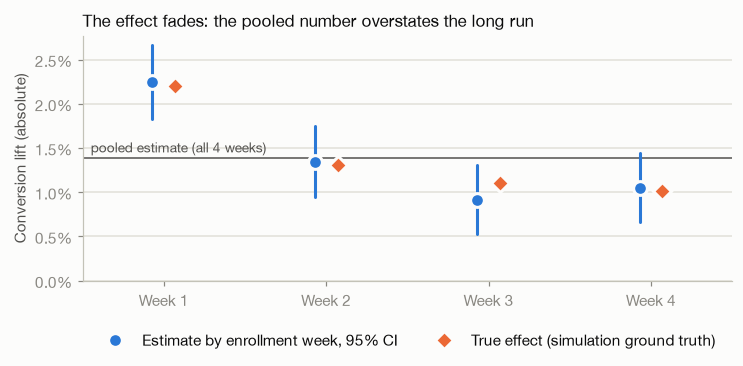

In [12]:
fig, ax = plt.subplots(figsize=(7.0, 3.5))
xs = wk_tab.index.to_numpy()
ax.axhline(pooled.estimate, color=INK2, lw=1)
ax.text(0.55, pooled.estimate + 0.0006, "pooled estimate (all 4 weeks)", color=INK2, fontsize=9, ha="left")
for x_, lo_, hi_ in zip(xs, wk_tab.ci_low, wk_tab.ci_high):
    ax.plot([x_ - 0.07, x_ - 0.07], [lo_, hi_], color=BLUE, lw=2, solid_capstyle="round")
ax.plot(xs - 0.07, wk_tab.estimate, "o", color=BLUE, ms=9, mec=SURFACE, mew=2, label="Estimate by enrollment week, 95% CI")
ax.plot(xs + 0.07, wk_tab["true effect"], "D", color=ORANGE, ms=8, mec=SURFACE, mew=2, label="True effect (simulation ground truth)")
ax.set_xticks(xs, [f"Week {w}" for w in xs]); ax.set_xlim(0.5, 4.5); ax.grid(axis="x", visible=False)
ax.set_ylabel("Conversion lift (absolute)"); ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.1%}")
ax.set_title("The effect fades: the pooled number overstates the long run", loc="left", fontsize=11, color=INK)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.tight_layout(); fig.savefig("../reports/figures/02_novelty.png", dpi=160, bbox_inches="tight"); plt.show()

The weekly estimates follow the truth and the decay is clear: the week-1 lift (~2.2 pp) is about twice the steady-state one (~1.0 pp), and the pooled estimate (~1.4 pp) is about 30% too high. Deciding after week 1 would count the benefit twice.

Ways to deal with it: run for at least 2 full weeks (which also covers weekday/weekend cycles), plot the effect by enrollment cohort and judge on the part where it has stabilized, keep a small long-term holdout after launch, and for first-exposure effects consider dropping the first days or ramping up traffic. The opposite case, a primacy effect where users resist a change at first and then adapt, is handled the same way.

Next: notebook 03 (uplift modelling, who benefits) and 04 (the real Hillstrom e-mail experiment).